In [26]:
import json
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


CHUNKS_DIR = Path("../matsne_data/chunks")

In [27]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(line) for line in f]


docs = load_jsonl(CHUNKS_DIR / "docs.jsonl")
parents = load_jsonl(CHUNKS_DIR / "parents.jsonl")
children = load_jsonl(CHUNKS_DIR / "children.jsonl")

print(f"Documents: {len(docs):,}")
print(f"Parents:   {len(parents):,}")
print(f"Children:  {len(children):,}")

Documents: 1,020
Parents:   10,288
Children:  14,715


In [28]:
docs_df = pd.DataFrame(docs)
parents_df = pd.DataFrame(parents)
children_df = pd.DataFrame(children)

docs_df.head()

,doc_id,url,number,type,authority,adopted,published,effective_from,expires,registration_code,...,last_amended,title_fallback,text_length,title,header_line,footer,annex_footers,preamble,n_parents,n_children
0,1209751,https://matsne.gov.ge/ka/document/view/1209751,3,მუნიციპალიტეტისა და თვითმმართველი ქალაქის საკრ...,მესტიის მუნიციპალიტეტი,2011-02-17,2011-02-28,NaN,NaN,010320000.35.103.016023,...,NaN,მესტიის მუნიციპალიტეტის წარმომადგენლობითი და ა...,1878,მესტიის მუნიციპალიტეტის წარმომადგენლობითი და ა...,NaN,NaN,None,NaN,0,0
1,1230221,https://matsne.gov.ge/ka/document/view/1230221,10,მუნიციპალიტეტისა და თვითმმართველი ქალაქის საკრ...,სამტრედიის მუნიციპალიტეტი,2011-03-04,2011-03-16,NaN,NaN,010250020.35.120.016028,...,2017-05-01,სამტრედიის მუნიციპალიტეტის ტერიტორიაზე ქონების...,4183,სამტრედიის მუნიციპალიტეტის ტერიტორიაზე ქონების...,NaN,NaN,None,NaN,0,0
2,1240084,https://matsne.gov.ge/ka/document/view/1240084,4397-Iს,საქართველოს კანონი,საქართველოს პარლამენტი,2011-03-11,2011-03-17,NaN,NaN,240090000.05.001.016208,...,NaN,„გეოლოგიური საქმიანობის ლიცენზიის გაცემის შესა...,552,„გეოლოგიური საქმიანობის ლიცენზიის გაცემის შესა...,NaN,NaN,None,NaN,0,0
3,1244901,https://matsne.gov.ge/ka/document/view/1244901,100,მუნიციპალიტეტისა და თვითმმართველი ქალაქის საკრ...,თვითმმართველი ქალაქი ქუთაისი,2011-03-14,2011-03-30,NaN,NaN,210020010.35.123.016052,...,2022-11-30,ქალაქ ქუთაისის მუნიციპალიტეტის ადმინისტრაციულ ...,49133,ქალაქ ქუთაისის მუნიციპალიტეტის ადმინისტრაციულ ...,NaN,NaN,None,NaN,0,0
4,1245629,https://matsne.gov.ge/ka/document/view/1245629,2,საქართველოს ეროვნული ბანკის საბჭოს დადგენილება,საქართველოს ეროვნული ბანკის საბჭო,2011-03-18,2011-03-24,NaN,NaN,220090000.11.004.016003,...,NaN,ლარის ბანკნოტებისა და მონეტების რეპროდუცირების...,4941,ლარის ბანკნოტებისა და მონეტების რეპროდუცირების...,NaN,NaN,None,NaN,0,0


In [30]:
parents_df["text_length"] = parents_df["text"].fillna("").str.len()

children_df["text_length"] = children_df["text"].fillna("").str.len()
children_df["retrieval_text_length"] = (
    children_df["retrieval_text"].fillna("").str.len()
)

In [35]:
def length_summary(df, column="text_length"):
    return (
        df[column]
        .describe(percentiles=[
            0.01,
            0.05,
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95,
            0.99,
        ])
        .to_frame()
        .T
        .round(0)
        .map(lambda x: f"{x:,.0f}")
    )

# Print len summary stats

In [36]:
print("DOCUMENTS")
display(length_summary(docs_df))

print("PARENTS")
display(length_summary(parents_df))

print("CHILDREN")
display(length_summary(children_df))

print("CHILDREN — RETRIEVAL TEXT")
display(length_summary(children_df, "retrieval_text_length"))

DOCUMENTS


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
text_length,"1,020","19,671","38,885",74,81,742,965,"1,486","7,356","24,204","49,103","71,601","175,647","611,588"


PARENTS


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
text_length,"10,288","1,747","3,738",8,51,53,122,295,866,"2,046","4,430","5,054","12,371","111,387"


CHILDREN


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
text_length,"14,715","1,193",829,7,43,53,130,369,"1,206","1,848","2,233","2,616","2,951","3,017"


CHILDREN — RETRIEVAL TEXT


,count,mean,std,min,1%,5%,10%,25%,50%,75%,90%,95%,99%,max
retrieval_text_length,"14,715","1,524",835,96,250,386,472,711,"1,544","2,176","2,589","2,960","3,277","3,656"


# Histograms

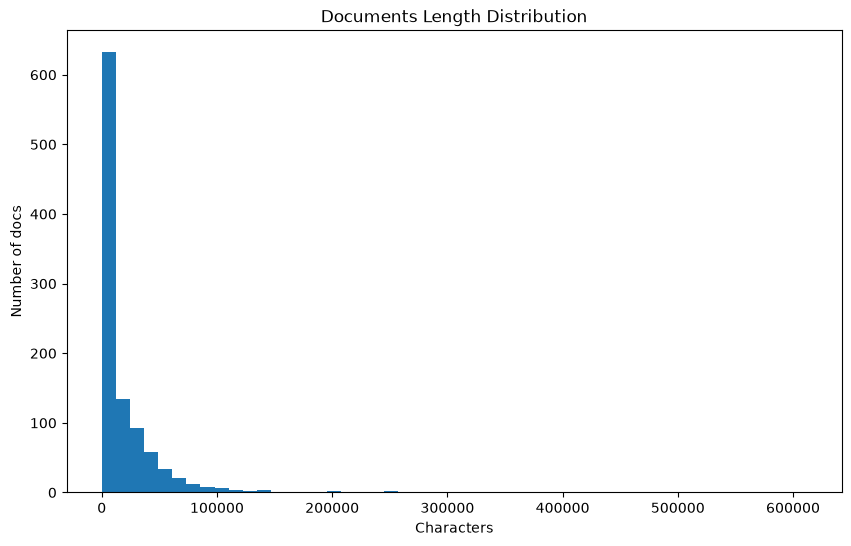

In [34]:
plt.figure(figsize=(10, 6))

plt.hist(docs_df["text_length"], bins=50)

plt.xlabel("Characters")
plt.ylabel("Number of docs")
plt.title("Documents Length Distribution")

plt.show()

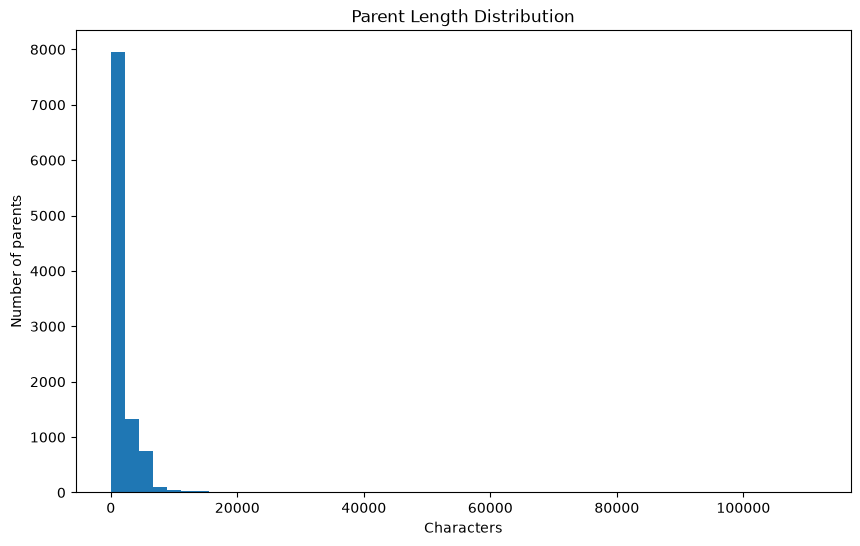

In [13]:
plt.figure(figsize=(10, 6))

plt.hist(parents_df["text_length"], bins=50)

plt.xlabel("Characters")
plt.ylabel("Number of parents")
plt.title("Parent Length Distribution")

plt.show()

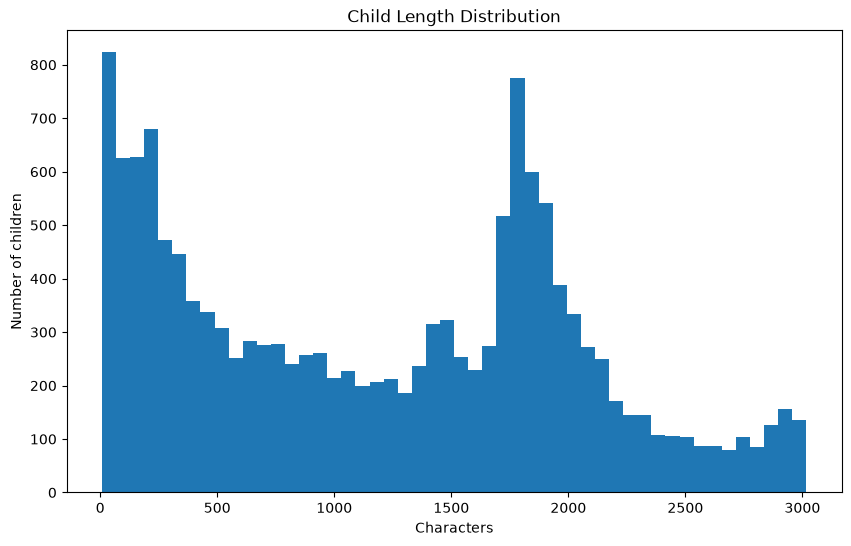

In [14]:
plt.figure(figsize=(10, 6))

plt.hist(children_df["text_length"], bins=50)

plt.xlabel("Characters")
plt.ylabel("Number of children")
plt.title("Child Length Distribution")

plt.show()

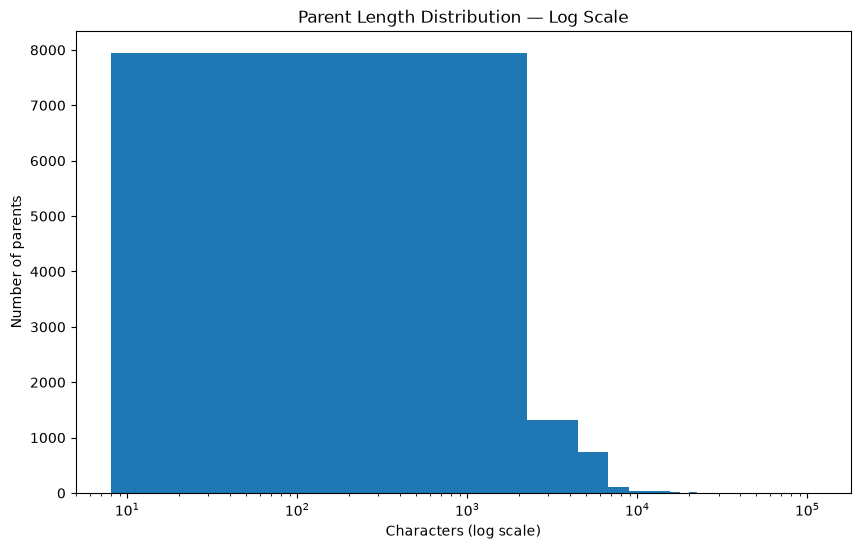

In [15]:
plt.figure(figsize=(10, 6))

plt.hist(parents_df["text_length"], bins=50)
plt.xscale("log")

plt.xlabel("Characters (log scale)")
plt.ylabel("Number of parents")
plt.title("Parent Length Distribution — Log Scale")

plt.show()

# Largest Parents

In [17]:
parents_df[
    ["parent_id", "text_length", "kind"]
].sort_values(
    "text_length",
    ascending=False
).head(20)

,parent_id,text_length,kind
9159,6656792:0004,111387,unit
1682,2634494:0015,107572,unit
1708,2636328:0013,99911,unit
1024,2159588:0015,96439,unit
3205,4234420:0004,83244,unit
10050,6873010:0004,83124,unit
245,1804818:0027,82287,unit
1336,2273401:0012,73032,unit
9348,6703385:0013,66832,unit
2151,3130110:0013,57032,unit


# Largest Children

In [20]:
children_df[
    ["chunk_id", "parent_id", "text_length", "kind"]
].sort_values(
    "text_length",
    ascending=False
).head(20)

,chunk_id,parent_id,text_length,kind
12370,6471596:0006:00,6471596:0006,3017,text
7973,5091917:0014:00,5091917:0014,3010,text
5578,4532387:0003:00,4532387:0003,3009,text
4983,4245919:0017:00,4245919:0017,3001,text
246,1804220:0018:00,1804220:0018,3001,text
8566,5425165:0006:00,5425165:0006,3001,text
13540,6720184:0003:09,6720184:0003,3000,table
13006,6701007:0067:00,6701007:0067,3000,table
10036,5835246:0013:01,5835246:0013,2999,text
13862,6733915:0004:00,6733915:0004,2998,table


In [22]:
MAX_CHILD = 3000

children_df[
    children_df["text_length"] >= 2800
][
    ["chunk_id", "parent_id", "kind", "text_length"]
].sort_values(
    "text_length",
    ascending=False
).head(50)

,chunk_id,parent_id,kind,text_length
12370,6471596:0006:00,6471596:0006,text,3017
7973,5091917:0014:00,5091917:0014,text,3010
5578,4532387:0003:00,4532387:0003,text,3009
8566,5425165:0006:00,5425165:0006,text,3001
4983,4245919:0017:00,4245919:0017,text,3001
246,1804220:0018:00,1804220:0018,text,3001
13006,6701007:0067:00,6701007:0067,table,3000
13540,6720184:0003:09,6720184:0003,table,3000
10036,5835246:0013:01,5835246:0013,text,2999
10528,5874397:0041:00,5874397:0041,text,2998


In [24]:
children_df[
    children_df["text_length"] > 3000
][
    ["chunk_id", "parent_id", "kind", "text_length"]
].sort_values(
    "text_length",
    ascending=False
)

,chunk_id,parent_id,kind,text_length
12370,6471596:0006:00,6471596:0006,text,3017
7973,5091917:0014:00,5091917:0014,text,3010
5578,4532387:0003:00,4532387:0003,text,3009
246,1804220:0018:00,1804220:0018,text,3001
4983,4245919:0017:00,4245919:0017,text,3001
8566,5425165:0006:00,5425165:0006,text,3001


In [25]:
children_df["retrieval_overhead"] = (
    children_df["retrieval_text_length"]
    - children_df["text_length"]
)

children_df["retrieval_overhead"].describe(
    percentiles=[
        0.5,
        0.75,
        0.90,
        0.95,
        0.99,
    ]
)

count    14715.000000
mean       331.749983
std        111.406038
min         71.000000
50%        317.000000
75%        405.000000
90%        493.000000
95%        532.000000
99%        610.860000
max        841.000000
Name: retrieval_overhead, dtype: float64